# 02 – A/B Testing: Is B really better than A?

**Business question:** A new landing page (B) was tested against the current one (A).
B converted more users in the test. Should the team roll B out?

**Data:** `ab_test.csv` — 20 simulated users, 10 per group (user_id, group, converted 0/1).

**Steps:** 1. load & validate · 2. conversion rates with confidence intervals · 3. significance tests ·
4. how big is the effect really? · 5. how many users would a reliable test need? · 6. decision

> Calculations live in `ab_testing.py`, tested in `tests/test_ab_testing.py` and cross-checked against `statsmodels`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import ab_testing as ab

df = ab.load_test()   # raises on unknown groups, non-binary outcomes or duplicate users
s = ab.summary(df)
s

,users,conversions,rate
group,,,
A,10,3,0.3
B,10,7,0.7


## 2. Conversion rates with 95 % confidence intervals (Wilson)

In [2]:
rows = []
for g in ["A", "B"]:
    x, n = int(s.loc[g, "conversions"]), int(s.loc[g, "users"])
    lo, hi = ab.wilson_ci(x, n)
    rows.append({"group": g, "rate": x / n, "ci_low": lo, "ci_high": hi})
ci = pd.DataFrame(rows).set_index("group")
ci.style.format("{:.1%}")

,rate,ci_low,ci_high
group,,,
A,30.0%,10.8%,60.3%
B,70.0%,39.7%,89.2%


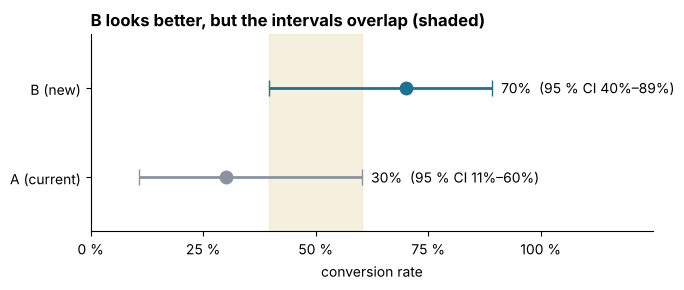

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
colors = {"A": "#8A94A0", "B": "#1C7293"}
for i, g in enumerate(["A", "B"]):
    r = ci.loc[g]
    ax.errorbar(r["rate"], i, xerr=[[r["rate"] - r["ci_low"]], [r["ci_high"] - r["rate"]]],
                fmt="o", color=colors[g], ms=9, capsize=6, lw=2)
    ax.text(r["ci_high"] + 0.02, i, f"{r['rate']:.0%}  (95 % CI {r['ci_low']:.0%}–{r['ci_high']:.0%})",
            va="center", fontsize=10)
ax.axvspan(ci.loc["B", "ci_low"], ci.loc["A", "ci_high"], color="#C9A227", alpha=0.15)
ax.set_yticks([0, 1]); ax.set_yticklabels(["A (current)", "B (new)"])
ax.set_xlim(0, 1.25); ax.set_xticks([0, .25, .5, .75, 1]); ax.set_xticklabels(["0 %", "25 %", "50 %", "75 %", "100 %"])
ax.set_ylim(-0.6, 1.6); ax.set_xlabel("conversion rate")
ax.set_title("B looks better, but the intervals overlap (shaded)", loc="left", fontsize=12, fontweight="bold")
for sp in ("top", "right"): ax.spines[sp].set_visible(False)
fig.tight_layout()
fig.savefig("figures/conversion_ci.png", dpi=130, bbox_inches="tight")
plt.show()

## 3. Significance tests (two-sided, α = 5 %)

In [4]:
t = ab.tests(3, 10, 7, 10)
pd.Series({"z statistic": t["z"], "p-value z-test": t["p_ztest"], "p-value Fisher's exact test": t["p_fisher"]}).round(3).to_frame("value")

,value
z statistic,1.789
p-value z-test,0.074
p-value Fisher's exact test,0.179


With 10 users per group the normal approximation behind the z-test is shaky, so **Fisher's exact test is the relevant one: p = 0.18**.
Even the more optimistic z-test (p = 0.074) stays above 0.05. **The difference is not statistically significant.**

## 4. How big is the effect really? — confidence interval for the difference B − A

In [5]:
lo, hi = ab.difference_ci(3, 10, 7, 10)
print(f"Observed difference: +{0.7 - 0.3:.0%} points")
print(f"95 % CI (Newcombe):  {lo:+.1%} to {hi:+.1%} points")

Observed difference: +40% points
95 % CI (Newcombe):  -2.9% to +67.2% points


The interval runs from **about −3 to +67 percentage points**. The data are compatible with B being slightly *worse*
and with B being dramatically better — the test simply has not narrowed it down.

## 5. How many users would a reliable test need?

In [6]:
print(f"Power of this test (n = 10 per group) for a true 30 % -> 70 % effect: {ab.power(0.3, 0.7, 10):.0%}")
plan = pd.DataFrame([
    {"baseline A": 0.30, "target B": pb, "lift (points)": pb - 0.30,
     "users per group": ab.sample_size_per_group(0.30, pb)}
    for pb in [0.70, 0.45, 0.40, 0.36, 0.33]
])
plan.style.format({"baseline A": "{:.0%}", "target B": "{:.0%}", "lift (points)": "{:+.0%}", "users per group": "{:,}"})

Power of this test (n = 10 per group) for a true 30 % -> 70 % effect: 43%


,baseline A,target B,lift (points),users per group
0,30%,70%,+40%,24
1,30%,45%,+15%,163
2,30%,40%,+10%,356
3,30%,36%,+6%,963
4,30%,33%,+3%,"3,763"


Even if the huge 40-point effect were real, a test with 10 users per group would detect it only **43 %** of the time.
Realistic page changes move conversion by a few points: detecting 30 % → 40 % needs **356 users per group**, 30 % → 33 % needs **3,763**.

## 6. Decision

| Question | Answer |
|---|---|
| Conversion A / B | 30 % / 70 % (3 of 10 vs. 7 of 10) |
| Significant at 5 %? | **No** — Fisher p = 0.18 (z-test p = 0.074) |
| 95 % CI of the difference | −2.9 to +67.2 percentage points |
| Power of this test for a 40-point effect | 43 % |
| Users per group for a 10-point lift | 356 |

**Recommendation:** do **not** roll out B on this evidence and do not discard it either. Define the smallest lift that matters
for the business *before* the next run, size the test for it (e.g. 356 users per group for +10 points at 80 % power),
and fix the run time in advance instead of stopping when the numbers look good.

**Limits:** simulated data; a real test also needs a check that users were randomly assigned and that both groups ran in the same period.